# Fred Lines in COMSOL field BL3_ESModel_11_26
## Revised with correct spacings
Now that we have data from the 3-axis field probe system in the delivered Cryogenic magnet we need to understand what we are seeing and how it compares to what we expect.

The field probe runs a 3-axis Hall probe calibrated up to 9 T along one of 5 axial tubes that run in inserts that can be put into either the trap region of the magnet or the proton detector region of the magnet. I believe that the idea is that the central tube will follow the lines of Fred's original s-line that runs along the center of the trap magnet to the point x=0, y=0, z=85.5 cm and then follows a line rotated 18° in the y-z plane along a line parallel to the axis of the bending magnet. The field probe adds lines parallel to the Fred line but translated by $\pm$3.9 cm in each of the z and y directions. Hower, because the probe only runs about half way through the system the mapping is done from both ends and the mapping in the bending magnet region is along lines parallel to the bending magnet axis while that in the trap region is done along lines parallel to the trap magnet and the neutron axis.

I made five lines by creating the Fred coordinates and then translating them in the x and y directions by $\pm$3.9 cm. For X this is trivial. For Y it is more complex. The Y translations are done in two parts. The first part is a simple shift to the right or left by 3.9 cm. This is applied to the portion of the track with s <= 85.5. The second part is a translation parallel to the bent beam axis by 3.9 cm. This alters both the Y and Z coordinates of each point. This means that the point s=100 cm corresponds to different values of Z for the three different tube position, Y=-3.9, Y=0, and Y=+3.9. We will see this in a quiver plot later on.

There is also the issue that the y and z components that I pull out are in the frame defined by the trap portion of the bore so that z is parallel to the neutron axis and y horizontal and perpendicular. When inserted in the trap bore this is (apart from probe mis-alignment) the frame of the field probe. However, when inserted in the bent bore the probe measures B parallel to the bent bore, at 18° to the neutron axis, and y, while still horizontal, is also rotated 18°. The computed fields have to be rotated to compensate for this before comparison with the measured data.

## Building tools

In [1]:
import numpy as np
import matplotlib.pyplot as plt

First I need a routine to read a file in. The files are COMSOL data files with a 9 line header followed by lines of 7 space-separated numbers. They are thus easy to read in with numpy.

To begin with I will just read them into a single array so we can look at them in raw form.

In [2]:
arr00 = np.loadtxt('NewFredLines11_4_26/YokedPDR8_FullAxisLineX0Y0.txt', skiprows=9)

Convention has us plotting the values against the 's' parameter which is the distance measured along the line. This is a little fiddly. For the first part it is just z. After that we have to add the distance from the bend to the z value at the bend. For this we need to know where the bend starts. The point at the bend is actually duplicated so that the first part of the line runs from row 0 to row 855 and then the bend line runs from row 856 to the end, row 1451.

In [3]:
s = arr00[:, 2].copy()

In [4]:
s[856:] = np.sqrt(arr00[856:, 1]**2 + (arr00[856:, 2] - arr00[855, 2])**2) + arr00[855, 2]

There, that should allow us to plot Fred's original curve, or a very close approximation.

Text(0.5, 1.0, 'Fred plot for field BL3_ESModel_11_26')

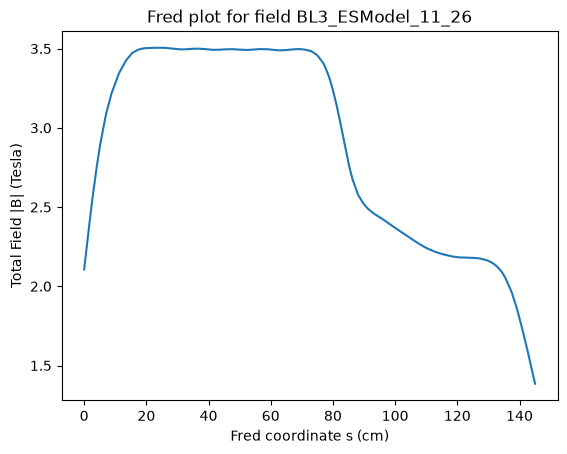

In [5]:
plt.plot(s, arr00[:, 6])
plt.xlabel('Fred coordinate s (cm)')
plt.ylabel('Total Field |B| (Tesla)')
plt.title('Fred plot for field BL3_ESModel_11_26')

Given that we can plot the un-corrected x and y fields. These are fields in the original axies where z is parallel to the neutron axis.

Text(0.5, 1.0, 'Vertical field component in BL3_ESModel_11_26')

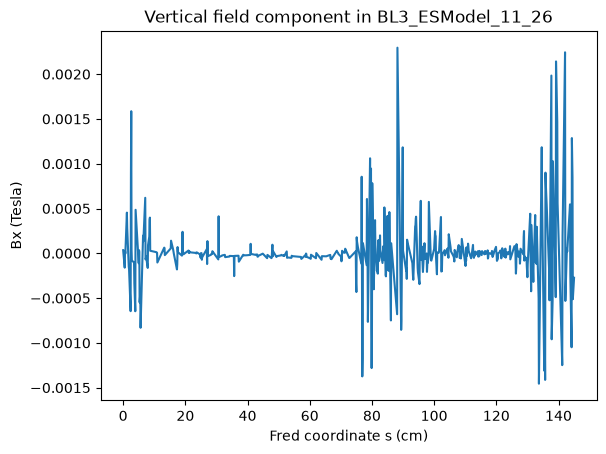

In [6]:
plt.plot(s, arr00[:, 3])
plt.xlabel('Fred coordinate s (cm)')
plt.ylabel('Bx (Tesla)')
plt.title('Vertical field component in BL3_ESModel_11_26')

As we expect, since this a symmetry plane, there is only model noise to be seen. The transverse Y field is rather different, of course.

Text(0.5, 1.0, 'Horizontal Y field component in BL3_ESModel_11_26')

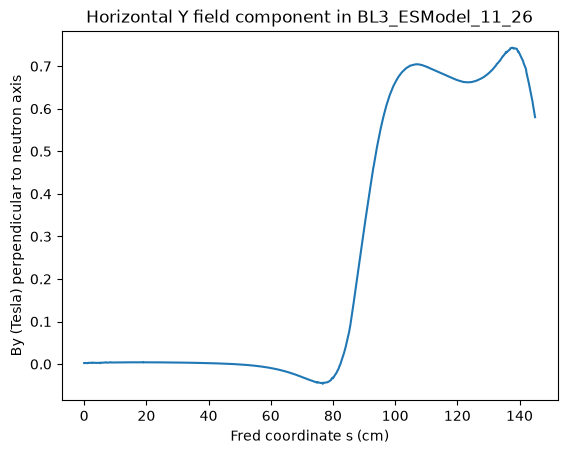

In [7]:
plt.plot(s, arr00[:, 4])
plt.xlabel('Fred coordinate s (cm)')
plt.ylabel('By (Tesla) perpendicular to neutron axis')
plt.title('Horizontal Y field component in BL3_ESModel_11_26')

and then the Bz is NOT the total field once we go round the bend because the direction of B is rotated relative to the s axis.

Text(0.5, 1.0, 'Horizontal Z field component in BL3_ESModel_11_26')

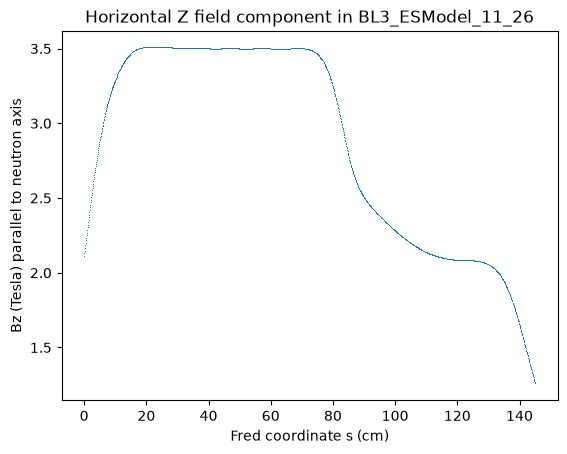

In [8]:
plt.plot(s, arr00[:, 5], ',')
plt.xlabel('Fred coordinate s (cm)')
plt.ylabel('Bz (Tesla) parallel to neutron axis')
plt.title('Horizontal Z field component in BL3_ESModel_11_26')

Now what happens when we correct the field so that it is always measured in the s frame? Well, if we denote components in the s-frame with a prime then we have
$$B_y' = B_y \cos(18°) - B_z \sin(18°)$$
$$B_z' = B_y \sin(18°) + B_z \cos(18°)$$
So precomputing the sine and cosine

In [9]:
degrees = np.pi / 180
c18 = np.cos(18 * degrees)
s18 = np.sin(18 * degrees)
print(s18, c18)

0.3090169943749474 0.9510565162951535


we can calculate the rotated B components. I start by copying each whole array and then modify only the rotated components.

In [10]:
B00xprime = arr00[:, 3].copy()
B00yprime = arr00[:, 4].copy()
B00zprime = arr00[:, 5].copy()
B00yprime[856:] = c18 * arr00[856:, 4] - s18 * arr00[856:, 5]
B00zprime[856:] = s18 * arr00[856:, 4] + c18 * arr00[856:, 5]

Then I can remake the plots.

Text(0.5, 1.0, 's-frame Y field component in BL3_ESModel_11_26')

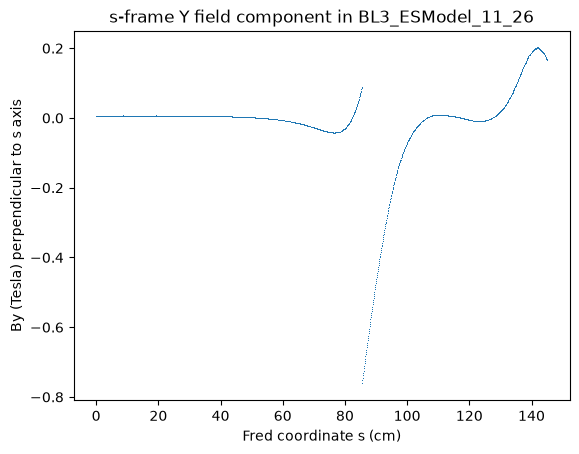

In [11]:
plt.plot(s, B00yprime, ',')
plt.xlabel('Fred coordinate s (cm)')
plt.ylabel('By (Tesla) perpendicular to s axis')
plt.title('s-frame Y field component in BL3_ESModel_11_26')

and the rip in the map is because what we are meausuring changes at the point. Bz' is a bit more sensible.

Text(0.5, 1.0, 's-frame Z field component in BL3_ESModel_11_26')

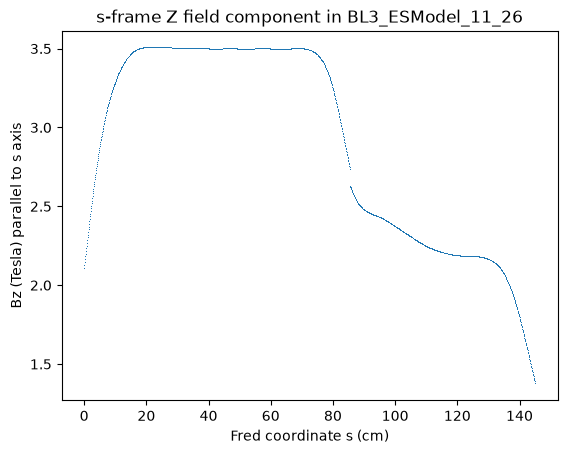

In [12]:
plt.plot(s, B00zprime, ',')
plt.xlabel('Fred coordinate s (cm)')
plt.ylabel('Bz (Tesla) parallel to s axis')
plt.title('s-frame Z field component in BL3_ESModel_11_26')

These look very abrupt and would lead to rather odd effects if the particles followed these paths. However the particles follow the B lines, which bend smoothly round the corners as can be seen in this figure
![Field lines in Yoked magnet](../PDR5YokedFieldLines7e.png)

If you look carefully then you can see the behavior that we have observed above. As the lines get towards the end of the trap they bend away from the positive y direction, leading to the small negative bump in y, before curving round the bend to become more parallel to the new magnet axis, returning By' to very small values. The abrupt fall in Bz' as we pass 85.5 cm is caused by the abrupt change in the angle at which we are measuring the field component. In the primed frame not only do we suffer the cos(18°) diminution in Bz but we also pick up an opposition from the By component.

Note: the fields in the figure above are not exactly correct because this figure is from a slightly earlier version of the magnet but the change is not one you could see on this scale. I will explore this in more detail below.

## Translation in the horizontal plane.

Now lets look at the same plots for the track that is translated by $\pm$ 0.39 cm in the positive y direction. The positive one is the path that lies on the inside of the curved bundle. I will denote this by arr0p indicating that the offset is positive (p) in the y direction. The one on the outside will be arr0m. I will plot both along with the center line on the graphs.

In [13]:
arr0p = np.loadtxt('NewFredLines11_4_26/YokedPDR8_FullAxisLineY+.txt', skiprows=9)
arr0m = np.loadtxt('NewFredLines11_4_26/YokedPDR8_FullAxisLineY-.txt', skiprows=9)

The Fred curve will not be much altered and there is little point in showing the Bx or Bz curves but the By will be worth looking at.

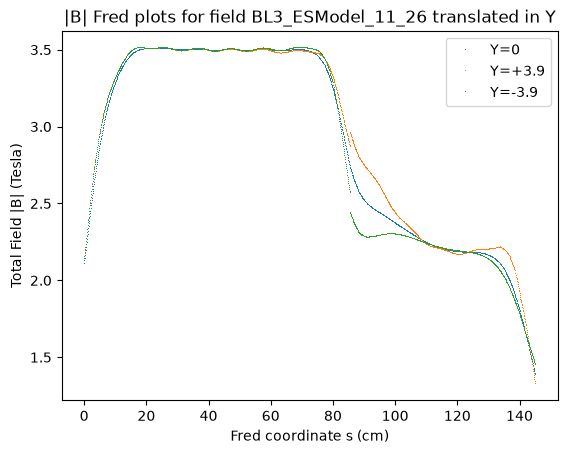

In [14]:
plt.plot(s, arr00[:, 6], ',', label='Y=0')
plt.plot(s, arr0p[:, 6], ',', label='Y=+3.9')
plt.plot(s, arr0m[:, 6], ',', label='Y=-3.9')
plt.xlabel('Fred coordinate s (cm)')
plt.ylabel('Total Field |B| (Tesla)')
plt.title('|B| Fred plots for field BL3_ESModel_11_26 translated in Y')
plt.legend()

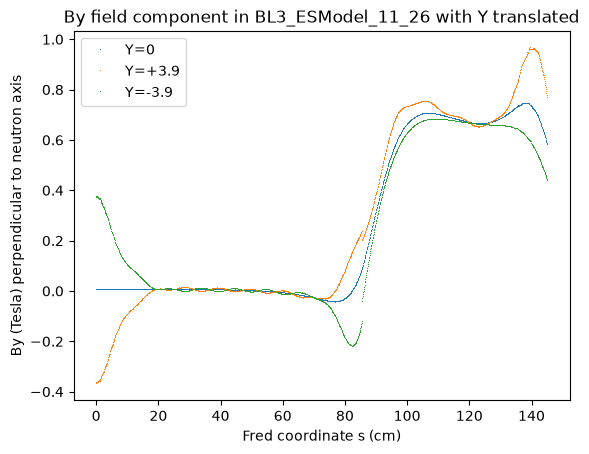

In [15]:
plt.plot(s, arr00[:, 4], ',', label='Y=0')
plt.plot(s, arr0p[:, 4], ',', label='Y=+3.9')
plt.plot(s, arr0m[:, 4], ',', label='Y=-3.9')
plt.xlabel('Fred coordinate s (cm)')
plt.ylabel('By (Tesla) perpendicular to neutron axis')
plt.title('By field component in BL3_ESModel_11_26 with Y translated')
plt.legend()

So the ones along the sides are close but differ noticeably in opposite directions. Not surprising. Now for the Y fields as directly measured by the probe, perpendicular to the local s-axis. What has appeared now are short breaks in the orange and green curves caused by the translations of the field probes being different for the region in the trap and in the bending magnet so that the end of one half of the track no longer arrives at the start of the other half, at least for the two Y translated probes.

In [16]:
B0pyprime = arr0p[:, 4].copy()
B0pyprime[856:] = c18 * arr0p[856:, 4] - s18 * arr0p[856:, 5]
B0myprime = arr0m[:, 4].copy()
B0myprime[856:] = c18 * arr0m[856:, 4] - s18 * arr0m[856:, 5]

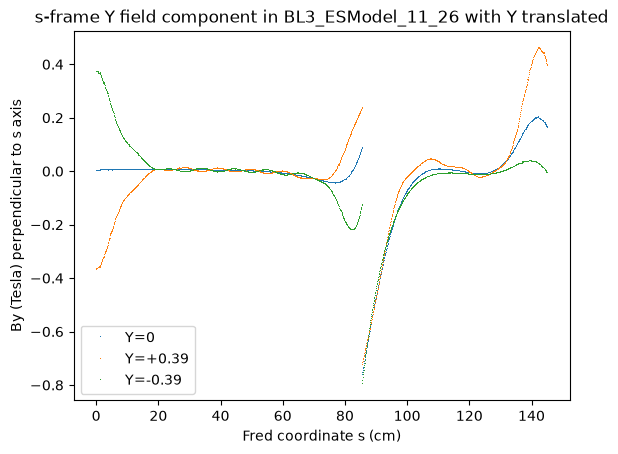

In [17]:
plt.plot(s, B00yprime, ',', label='Y=0')
plt.plot(s, B0pyprime, ',', label='Y=+0.39')
plt.plot(s, B0myprime, ',', label='Y=-0.39')
plt.xlabel('Fred coordinate s (cm)')
plt.ylabel('By (Tesla) perpendicular to s axis')
plt.title('s-frame Y field component in BL3_ESModel_11_26 with Y translated')
plt.legend()

Same idea. Small changes, largest at the extremes.

## Quiver plots

Another way to look at the field, which is particularly useful for these fields, is the quivver plot which plots the field direction at each point along the trajectory. Since the fields so far are measured in the x=0 symmetry plane there is no confusing x component to worry about. In order clearly to see the mis-alignment that I am talking about we will focus on the region right near the kink.

Text(0, 0.5, 'X (cm)')

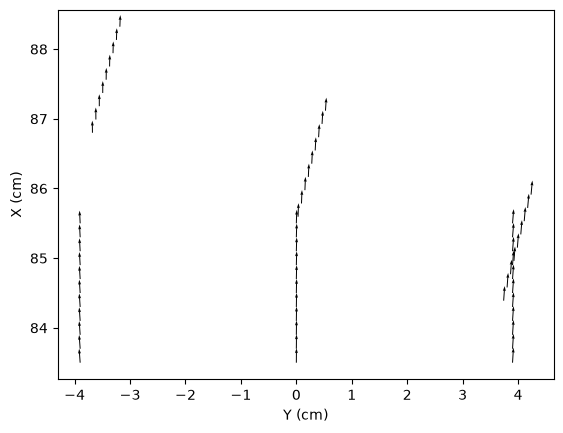

In [18]:
kink_idx = 855
irange = 20
step = 2
start = kink_idx - irange
stop = kink_idx + irange
mag=100
plt.quiver(arr00[start:stop:step, 1], arr00[start:stop:step, 2], 
           arr00[start:stop:step, 4], arr00[start:stop:step, 5],
           scale=mag, width=0.002)
plt.quiver(arr0m[start:stop:step, 1], arr0m[start:stop:step, 2], 
           arr0m[start:stop:step, 4], arr0m[start:stop:step, 5],
           scale=mag, width=0.002)
plt.quiver(arr0p[start:stop:step, 1], arr0p[start:stop:step, 2], 
           arr0p[start:stop:step, 4], arr0p[start:stop:step, 5],
           scale=mag, width=0.002)
#plt.ylim(80, 89)
#plt.xlim(-4, 5)
plt.xlabel('Y (cm)')
plt.ylabel('X (cm)')

So here the effect of the difference in translation in the two halves of the track. In the bottom part of the picture the three tracks are simply displaced in the Y direction. However, beyond that the displacement it perpendicular to the new center line, at 18° to the old center line. This means that while the central tracks still meet in the middle the ones on the sides are arriving at rather different points in space.

There is a second effect from this. The number of the arrow is linearly related to its position in s-space. For the portion of the track in the trap region the s-value corresponds directly with Z. However, for the measurments in the bending magnet this relationship is broken. The first arrow beyond break corresponds to three different values of Z that differ by a total of almost two centimeters. This will be an important consideration when trying build a large-scale model of the field in the region round the kink.

The other thing that we can learn from this figure is why we get the abrupt discontinuities in the measured probe values. The effect ismost obvious for the off-axis probes but if you look carefully at even the central track we see the origin of the break in the graph.

Looking at the point of the kink on the central track, where there is no dislocation, we see that the angles of the arrows change very slowly while the angle of line changes abruptly. So that the field at the end of the straight part of the path has a tiny positive horizontal component in the trap frame (Z vertical) but the field seen in the bent frame (Z' at 18° to the vertical) has a large negative horizontal component. Here are the numbers:

In [19]:
print(arr00[kink_idx, 4], arr00[kink_idx, 5], 'at', arr00[kink_idx, 1], arr00[kink_idx, 2])

0.086548 2.7321 at 0.0 85.5


and the field at 

In [20]:
print(arr00[kink_idx+1, 4], arr00[kink_idx+1, 5], 'at', arr00[kink_idx+1, 1], arr00[kink_idx+1, 2])

0.086548 2.7321 at 0.0 85.5


are identical but when we rotate the second one into the rotated coordinate frame we get

In [21]:
print(c18 * arr0p[856, 4] - s18 * arr0p[856, 5], s18 * arr0p[856, 4] + c18 * arr0p[856, 5])

-0.7233812782740183 2.8669830287503704


and we see that sudden large change in By' that arises only from the shift in orientation. The field still points slightly to the right of the z axis but with our components now measured relative to the angled line the numbers that the probe reports have changed by a large amount.

## Translations in the vertical plane

Once we translate the probe axis in the vertical direction we are no longer exactly in a symmetry plane and we pick up a small x component as we shall see. First the raw fields.

In [22]:
arrp0 = np.loadtxt('NewFredLines11_4_26/YokedPDR8_FullAxisLineX+.txt', skiprows=9)
arrm0 = np.loadtxt('NewFredLines11_4_26/YokedPDR8_FullAxisLineX-.txt', skiprows=9)

Again the Fred curve is not terribly interesting.

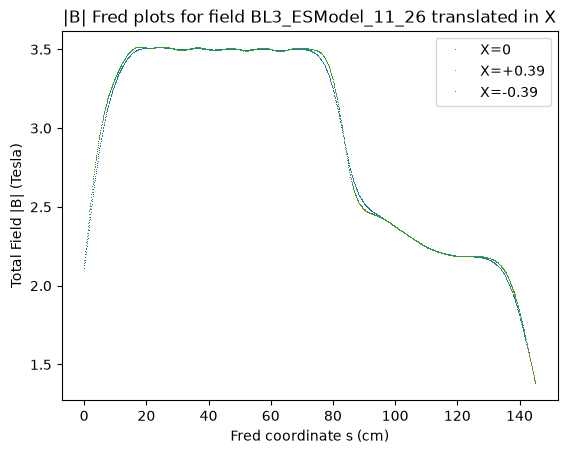

In [23]:
plt.plot(s, arr00[:, 6], ',', label='X=0')
plt.plot(s, arrp0[:, 6], ',', label='X=+0.39')
plt.plot(s, arrm0[:, 6], ',', label='X=-0.39')
plt.xlabel('Fred coordinate s (cm)')
plt.ylabel('Total Field |B| (Tesla)')
plt.title('|B| Fred plots for field BL3_ESModel_11_26 translated in X')
plt.legend()

We actually see a little more variation in the region of the bend when we go up and down that we saw by going from side to side.

The most interesting is the new Bx plot. Unlike the By plot this one is unaffected by the kink in the s axis and so actually represents what we expect from a perfectly aligned probe.

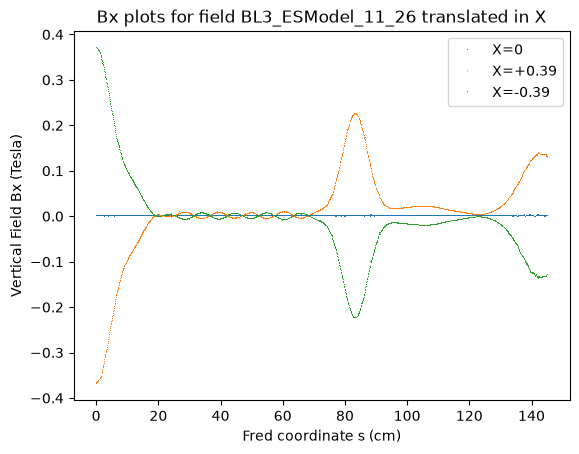

In [24]:
plt.plot(s, arr00[:, 3], ',', label='X=0')
plt.plot(s, arrp0[:, 3], ',', label='X=+0.39')
plt.plot(s, arrm0[:, 3], ',', label='X=-0.39')
plt.xlabel('Fred coordinate s (cm)')
plt.ylabel('Vertical Field Bx (Tesla)')
plt.title('Bx plots for field BL3_ESModel_11_26 translated in X')
plt.legend()

The symmetry is extremely encouraging as it should be gauranteed by the reflection symmetry in the y-z plane.

Again, By and Bz are not what the probe will read.

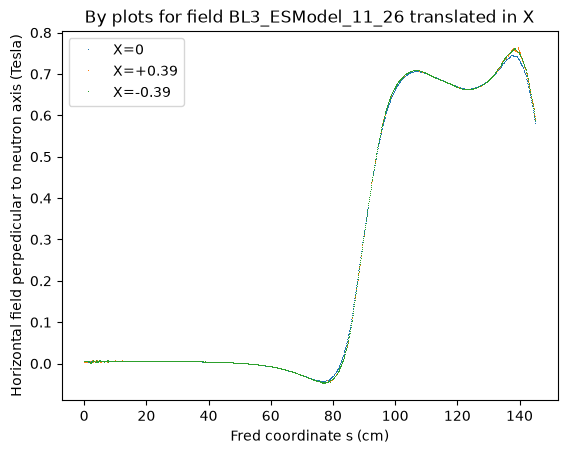

In [25]:
plt.plot(s, arr00[:, 4], ',', label='X=0')
plt.plot(s, arrp0[:, 4], ',', label='X=+0.39')
plt.plot(s, arrm0[:, 4], ',', label='X=-0.39')
plt.xlabel('Fred coordinate s (cm)')
plt.ylabel('Horizontal field perpedicular to neutron axis (Tesla)')
plt.title('By plots for field BL3_ESModel_11_26 translated in X')
plt.legend()

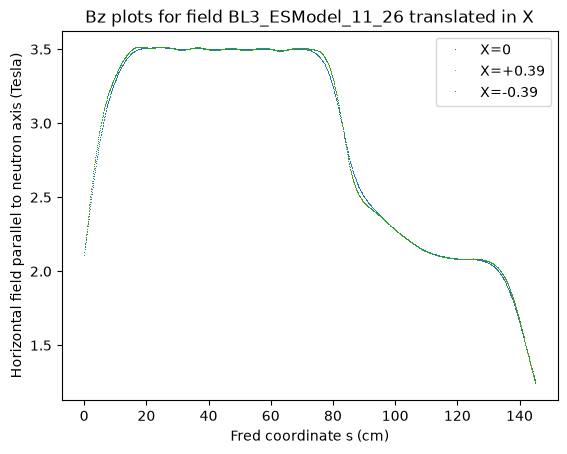

In [26]:
plt.plot(s, arr00[:, 5], ',', label='X=0')
plt.plot(s, arrp0[:, 5], ',', label='X=+0.39')
plt.plot(s, arrm0[:, 5], ',', label='X=-0.39')
plt.xlabel('Fred coordinate s (cm)')
plt.ylabel('Horizontal field parallel to neutron axis (Tesla)')
plt.title('Bz plots for field BL3_ESModel_11_26 translated in X')
plt.legend()

More interesting are the primed fields that give us a view of what the probe should measure.

In [27]:
Bp0yprime = arrp0[:, 4].copy()
Bp0yprime[856:] = c18 * arrp0[856:, 4] - s18 * arrp0[856:, 5]
Bm0yprime = arrm0[:, 4].copy()
Bm0yprime[856:] = c18 * arrm0[856:, 4] - s18 * arrm0[856:, 5]

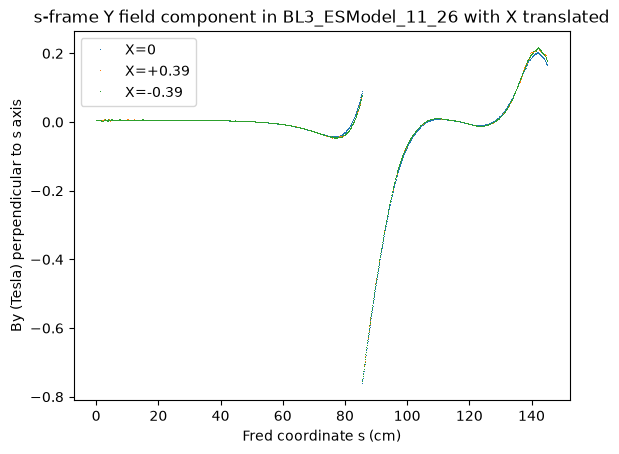

In [28]:
plt.plot(s, B00yprime, ',', label='X=0')
plt.plot(s, Bp0yprime, ',', label='X=+0.39')
plt.plot(s, Bm0yprime, ',', label='X=-0.39')
plt.xlabel('Fred coordinate s (cm)')
plt.ylabel('By (Tesla) perpendicular to s axis')
plt.title('s-frame Y field component in BL3_ESModel_11_26 with X translated')
plt.legend()

In [29]:
Bp0zprime = arrp0[:, 5].copy()
Bp0zprime[856:] = s18 * arrp0[856:, 4] + c18 * arrp0[856:, 5]
Bm0zprime = arrm0[:, 5].copy()
Bm0zprime[856:] = s18 * arrm0[856:, 4] + c18 * arrm0[856:, 5]


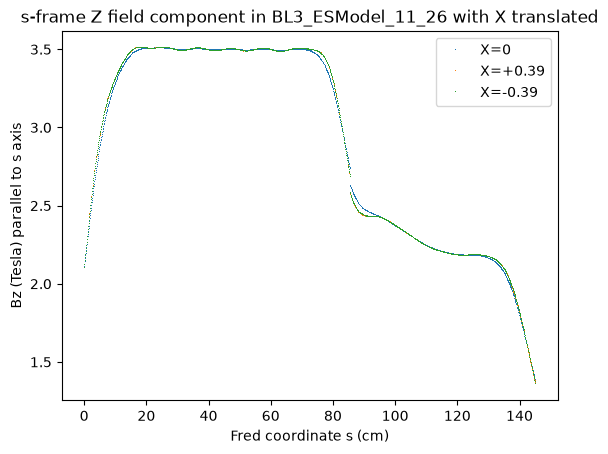

In [30]:
plt.plot(s, B00zprime, ',', label='X=0')
plt.plot(s, Bp0zprime, ',', label='X=+0.39')
plt.plot(s, Bm0zprime, ',', label='X=-0.39')
plt.xlabel('Fred coordinate s (cm)')
plt.ylabel('Bz (Tesla) parallel to s axis')
plt.title('s-frame Z field component in BL3_ESModel_11_26 with X translated')
plt.legend()

Again, the lines away from the symmetry plane show more deformation in the bend region.